In [92]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, StateGraph
from typing_extensions import Annotated,TypedDict
from langgraph.graph.message import add_messages

In [93]:
# 1. Define State
class State(TypedDict):
  messages: Annotated[list, add_messages]

In [94]:
def bot_node(state: State):
    return {"messages": ["Hello! How can I help you?"]}

In [95]:
# build graph
workflow = StateGraph(State)
workflow.add_node("bot", bot_node)
workflow.set_entry_point("bot")
workflow.add_edge("bot", END)

In [96]:
# 3. Add Checkpointer during compilation
checkpointer = MemorySaver()
app = workflow.compile(checkpointer=checkpointer)

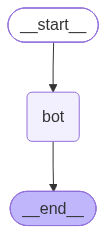

In [97]:
app

In [81]:
# Session 1 for User A
config = {"configurable": {"thread_id": "user_session_123"}}

# First turn
result1 = app.invoke({"messages": ["Hi"]}, config=config)

# Fetch current snapshot from memory anytime
snapshot = app.get_state(config)
print("Saved State Snapshot:", snapshot.values)

Saved State Snapshot: {'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='a16cc039-7989-49a9-b099-75e4876d18e7'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='d3bb2bfa-11d0-491c-8813-dfb607e2795e')]}


In [98]:
# Session 1 for User A
config = {"configurable": {"thread_id": "user_session_456"}}

# First turn
result1 = app.invoke({"messages": ["Hello from otherside"]}, config=config)

# Fetch current snapshot from memory anytime
snapshot = app.get_state(config)
print("Saved State Snapshot:", snapshot.values)

Saved State Snapshot: {'messages': [HumanMessage(content='Hello from otherside', additional_kwargs={}, response_metadata={}, id='b210de59-bf89-4208-b4e9-99cb2e663685'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='7209ea61-a9df-4611-97db-ae3725d2267a')]}


In [100]:
# Session 1 for User A
config = {"configurable": {"thread_id": "user_session_456"}}

# First turn
result1 = app.invoke({"messages": ["Hello namaste"]}, config=config)

# Fetch current snapshot from memory anytime
snapshot = app.get_state(config)
print("Saved State Snapshot:", snapshot.values)

Saved State Snapshot: {'messages': [HumanMessage(content='Hello from otherside', additional_kwargs={}, response_metadata={}, id='b210de59-bf89-4208-b4e9-99cb2e663685'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='7209ea61-a9df-4611-97db-ae3725d2267a'), HumanMessage(content='Hello namaste', additional_kwargs={}, response_metadata={}, id='a36f5f4a-03a1-4d9d-ade2-d6547936419a'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='b27b8713-ed23-407a-9caa-238600221da5'), HumanMessage(content='Hello namaste', additional_kwargs={}, response_metadata={}, id='93ac20aa-b511-4c07-9ab9-67193a0e0f1b'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='f7f1147b-1651-404b-bf41-205ecec62fc4')]}


In [101]:
config = {"configurable": {"thread_id": "user_session_456"}}

# Stream values with the config so the checkpointer records and updates the thread
for event in app.stream(
    {"messages": ["Hello, remember this thread"]},
    config=config,
    stream_mode="values",
):
  print(event)
  print("-" * 40)

{'messages': [HumanMessage(content='Hello from otherside', additional_kwargs={}, response_metadata={}, id='b210de59-bf89-4208-b4e9-99cb2e663685'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='7209ea61-a9df-4611-97db-ae3725d2267a'), HumanMessage(content='Hello namaste', additional_kwargs={}, response_metadata={}, id='a36f5f4a-03a1-4d9d-ade2-d6547936419a'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='b27b8713-ed23-407a-9caa-238600221da5'), HumanMessage(content='Hello namaste', additional_kwargs={}, response_metadata={}, id='93ac20aa-b511-4c07-9ab9-67193a0e0f1b'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='f7f1147b-1651-404b-bf41-205ecec62fc4'), HumanMessage(content='Hello, remember this thread', additional_kwargs={}, response_metadata={}, id='6c2f1a87-da72-47a6-aebd-b69506b479f3')]}
----------------------------------------
{'

In [80]:
config = {"configurable": {"thread_id": "user_session_456"}}

# Stream values with the config so the checkpointer records and updates the thread
for event in app.stream(
    {"messages": ["Hello, my name is karthik"]},
    config=config,
    stream_mode="values",
):
  print(event)
  print("-" * 40)

{'messages': [HumanMessage(content='Hello from otherside', additional_kwargs={}, response_metadata={}, id='237b9704-17d8-4fee-bdb7-116d5594aa75'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='244a6d0a-5444-40b3-bcd8-24b58b04361d'), HumanMessage(content='Hello namaste', additional_kwargs={}, response_metadata={}, id='0e76812e-a262-4eb9-bd37-74a61f6e2bf6'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='01947436-c346-4a23-a604-79201663134b'), HumanMessage(content='Hello, remember this thread', additional_kwargs={}, response_metadata={}, id='632cdc24-d127-44b5-8371-dd03a3bc2fa6'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='071e3955-8ca4-4400-8527-21603605bd0f'), HumanMessage(content='Hello, my name is karthik', additional_kwargs={}, response_metadata={}, id='462eb43b-754e-4e3c-8988-6d2142cde39b')]}
-------------------------------

In [102]:
config = {"configurable": {"thread_id": "user_session_123"}}

# Stream values with the config so the checkpointer records and updates the thread
for event in app.stream(
    {"messages": ["Hello, remember this thread"]},
    config=config,
    stream_mode="values",
):
  messages = event.get("messages",[])

  print(messages)
  print("-" * 40)

[HumanMessage(content='Hello, remember this thread', additional_kwargs={}, response_metadata={}, id='f3fa7d83-c68b-402c-a910-fead743bf2f3')]
----------------------------------------
[HumanMessage(content='Hello, remember this thread', additional_kwargs={}, response_metadata={}, id='f3fa7d83-c68b-402c-a910-fead743bf2f3'), HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='1d1af07c-9450-4ba4-a99e-04771e340c5d')]
----------------------------------------


Key Takeaways for Persistence
checkpointer: Compiles into the graph (checkpointer=MemorySaver() for in-memory, or PostgresSaver / SqliteSaver for production databases).

config={"configurable": {"thread_id": "..."}}: The unique key used to isolate state snapshots per conversation thread.

app.get_state(config): Allows you to inspect the exact state saved at the current checkpoint.

Run this snippet in your environment or take a look at the mechanics—how does this mental model of checkpointing and thread IDs feel?

In [103]:
config = {"configurable": {"thread_id": "user_session_789"}}

app.invoke({"messages": ["Hi"]}, config=config)
app.invoke({"messages": ["How are you?"]}, config=config)

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='5dc146c8-1f8c-4526-9845-dc5120c2a64f'),
  HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='3fae4b18-07dc-49aa-97d8-02b68de687f1'),
  HumanMessage(content='How are you?', additional_kwargs={}, response_metadata={}, id='4a642c42-249f-4cf7-a342-6a6ed7581cb0'),
  HumanMessage(content='Hello! How can I help you?', additional_kwargs={}, response_metadata={}, id='fb3dee9a-2b48-4fb2-bfb2-f77302b51467')]}

stream_mode="values" returns the entire state after each step.



stream_mode="updates" returns only the changes produced by each node, not the entire state.